# Deep Network Development, 2026 Autumn — Week 9 Practice
## NumPy data preparation, classification, and model evaluation

**Dataset:** [Dry Bean, UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/602/dry+bean+dataset) (13,611 observations, 16 numerical features, 7 classes). Dataset DOI: [10.24432/C50S4B](https://doi.org/10.24432/C50S4B), CC BY 4.0. Based on work by M. Koklu and I. A. Özkan (2020).

**Learning goals:** (1) clean and reconstruct features using NumPy, (2) prevent data leakage, (3) establish simple classification baselines, (4) train a PyTorch MLP, (5) calculate classification metrics and confusion matrices without metrics libraries, and (6) plot learning curves and select a model.

**Libraries:** NumPy for **all** reading, splitting, shuffling, imputation, feature operations, scaling, and evaluation; PyTorch **only** for tensors, DataLoader, model, optimizer, and training; Matplotlib for plotting. **No pandas or scikit-learn.**

**Before you begin:** Obtain the CSV named `Dry_Bean_Dataset_missing.csv` from [this public CSV mirror](https://www.stat.rice.edu/~scottdw/stat541/PROJECTS/uci-data/DRY-BEAN/Dry_Bean_Dataset.csv), or convert the official [UCI Dry Bean XLSX/ARFF release](https://archive.ics.uci.edu/dataset/602/dry+bean+dataset) to CSV **before class**. Place the CSV next to this notebook. The CSV must have a header, **16 feature columns followed by `Class`**. The notebook intentionally does not install packages or use a CSV downloader.

## Provided setup: imports and reproducibility

In [21]:
import copy
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cpu")

## Exercise 1: Load, inspect, shuffle, and split

**Your task:**
1. Read the CSV with **`np.genfromtxt`** (not pandas). Convert the first 16 columns to `float64` and encode `Class` labels as integers with `np.unique(..., return_inverse=True)`.
2. Check shape, missing values, class names, and class frequencies. Display a bar chart of the counts.
3. Using `rng.permutation`, shuffle **rows**, keeping features and labels aligned. Split into **70% train, 15% validation, and 15% test** using NumPy indexing/slicing only.
4. Print shapes and counts for each partition. Do not compute imputation or scaling statistics on the combined dataset.

**Check:** Shuffling rows preserves each sample's label. Shuffling columns changes the meaning of feature positions.

In [22]:

X = np.genfromtxt("Dry_Bean_Dataset_missing.csv", delimiter=",", skip_header=1, usecols=range(16), dtype=np.float64)
raw_labels = np.genfromtxt("Dry_Bean_Dataset_missing.csv", delimiter=",", skip_header=1, usecols=16, dtype=str)

class_names, y = np.unique(raw_labels, return_inverse=True)

print("X shape:", X.shape, "| y shape:", y.shape)
print("Missing values in X:", np.isnan(X).sum())

X shape: (13611, 16) | y shape: (13611,)
Missing values in X: 2448


Class 'BARBUNYA': 1322
Class 'BOMBAY': 522
Class 'CALI': 1630
Class 'DERMASON': 3546
Class 'HOROZ': 1928
Class 'SEKER': 2027
Class 'SIRA': 2636


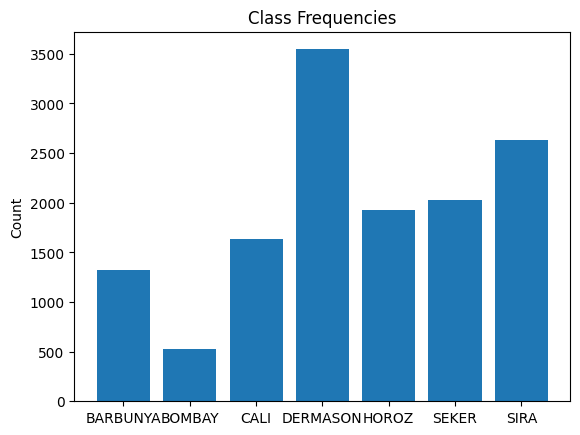

In [23]:
counts = np.bincount(y)
for name, count in zip(class_names, counts):
    print(f"Class '{name}': {count}")

plt.bar(class_names, counts)
plt.title("Class Frequencies")
plt.ylabel("Count")
plt.show()

In [24]:
rng = np.random.default_rng(seed=42)
perm = rng.permutation(len(X))
X, y = X[perm], y[perm]

n = len(X)
train_end = int(0.70 * n)
val_end = int(0.85 * n)

X_train, y_train = X[:train_end], y[:train_end]
X_val, y_val = X[train_end:val_end], y[train_end:val_end]
X_test, y_test = X[val_end:], y[val_end:]

for split_name, X_part, y_part in [
    ("Train", X_train, y_train),
    ("Val", X_val, y_val),
    ("Test", X_test, y_test),
]:
    print(
        f"{split_name} -> X: {X_part.shape}, y: {y_part.shape}, counts: {np.bincount(y_part)}"
    )


Train -> X: (9527, 16), y: (9527,), counts: [ 914  364 1157 2514 1347 1413 1818]
Val -> X: (2042, 16), y: (2042,), counts: [193  85 246 521 291 297 409]
Test -> X: (2042, 16), y: (2042,), counts: [215  73 227 511 290 317 409]


## Exercise 2: Data cleaning and imputation

**Your task:**

1. Count missing entries per feature using `np.isnan()` and `np.sum()`. Identify extreme values and compare means and medians.

2. **Create missing-value indicator features.** Before imputation, create a binary indicator column for each original feature containing missing values:
   - `1` if the original value was missing (`NaN`).
   - `0` otherwise.

   Append these indicator columns using `np.column_stack()` or `np.concatenate()`. Ensure training, validation, and test datasets use the same indicator columns in the same order.

3. Implement `impute_with_training_statistics(X_train, X_val, X_test, strategy)`.
   - Support both `'mean'` and `'median'`.
   - Calculate statistics using only the training data.
   - Ignore missing values using `np.nanmean()` or `np.nanmedian()`.
   - Apply the training statistics to all three datasets.
   - Do not modify the original arrays.

4. Create two cleaned versions of the dataset using mean and median imputation.

5. Append the missing-value indicators to the imputed data and verify that all feature values are finite using `np.isfinite()`.

**Questions:**

- Why must missing-value indicators be created before imputation?
- Why should the imputation statistics be calculated exclusively from the training set?
- What additional information can a missing-value indicator provide to a neural network?

In [26]:
missing_per_col = np.isnan(X_train).sum(axis=0)
means = np.nanmean(X_train, axis=0)
medians = np.nanmedian(X_train, axis=0)
mins = np.nanmin(X_train, axis=0)
maxs = np.nanmax(X_train, axis=0)

In [38]:
summary_table = np.column_stack([np.arange(X_train.shape[1]), missing_per_col, means, medians, mins, maxs])
np.set_printoptions(precision=2, suppress=True)
print(" Col      | Missing       | Mean  | Median    | Min    | Max")
print(summary_table)


 Col      | Missing       | Mean  | Median    | Min    | Max
[[     0.        0.    52990.14  44628.    20464.   254616.  ]
 [     1.      286.      854.95    794.58    524.74   1985.37]
 [     2.        0.      319.95    297.08    183.97    738.86]
 [     3.      277.      202.23    192.41    130.74    460.2 ]
 [     4.        0.        1.58      1.55      1.02      2.36]
 [     5.      262.        0.75      0.76      0.22      0.91]
 [     6.        0.    53707.76  45132.    20772.   263261.  ]
 [     7.        0.      252.9     238.37    161.42    569.37]
 [     8.      286.        0.75      0.76      0.57      0.87]
 [     9.        0.        0.99      0.99      0.94      0.99]
 [    10.        0.        0.87      0.88      0.49      0.99]
 [    11.      277.        0.8       0.8       0.65      0.99]
 [    12.        0.        0.01      0.01      0.        0.01]
 [    13.        0.        0.        0.        0.        0.  ]
 [    14.      275.        0.64      0.64      0.42      

In [40]:
missing_cols = np.where(missing_per_col > 0)

ind_train = np.isnan(X_train[:, missing_cols]).astype(np.float64)
ind_val = np.isnan(X_val[:, missing_cols]).astype(np.float64)
ind_test = np.isnan(X_test[:, missing_cols]).astype(np.float64)

In [41]:
def impute_with_training_statistics(X_train, X_val, X_test, strategy="mean"):
    if strategy == "mean":
        stats = np.nanmean(X_train, axis=0)
    elif strategy == "median":
        stats = np.nanmedian(X_train, axis=0)
    else:
        raise ValueError("strategy must be 'mean' or 'median'")

   
    X_tr_clean = np.where(np.isnan(X_train), stats, X_train)
    X_va_clean = np.where(np.isnan(X_val), stats, X_val)
    X_te_clean = np.where(np.isnan(X_test), stats, X_test)

    return X_tr_clean, X_va_clean, X_te_clean



In [ ]:

X_tr_mean, X_va_mean, X_te_mean = impute_with_training_statistics(X_train, X_val, X_test, "mean")
X_tr_med, X_va_med, X_te_med = impute_with_training_statistics(X_train, X_val, X_test, "median")


X_tr_mean_full = np.column_stack([X_tr_mean, ind_train])
X_va_mean_full = np.column_stack([X_va_mean, ind_val])
X_te_mean_full = np.column_stack([X_te_mean, ind_test])

X_tr_med_full = np.column_stack([X_tr_med, ind_train])
X_va_med_full = np.column_stack([X_va_med, ind_val])
X_te_med_full = np.column_stack([X_te_med, ind_test])

assert np.isfinite(X_tr_mean_full).all() and np.isfinite(X_tr_med_full).all()
assert np.isfinite(X_va_mean_full).all() and np.isfinite(X_va_med_full).all()
assert np.isfinite(X_te_mean_full).all() and np.isfinite(X_te_med_full).all()
print("All arrays verified finite. Final shape:", X_tr_med_full.shape)


ValueError: all the input arrays must have same number of dimensions, but the array at index 0 has 2 dimension(s) and the array at index 1 has 3 dimension(s)

## Exercise 3: Column reconstruction and feature engineering

The 16 features are in UCI order. **Use one-based column numbers in the instructions; NumPy indices start at 0.** Create a new 16-column matrix:

- Keep **columns 1–10** unchanged (`X[:, :10]`).
- **Replace columns 11–13** with three computed features.
- Keep **columns 14–16** unchanged (`X[:, 13:]`).

Use the source features `Area` (index 0), `Perimeter` (1), `MajorAxisLength` (2), `MinorAxisLength` (3), and `EquivDiameter` (7):

$$
\text{Roundness}=\frac{4\pi\,\text{Area}}{\text{Perimeter}^{2}}
$$

$$
\text{Compactness}=\frac{\text{EquivDiameter}}{\text{MajorAxisLength}}
$$

$$
\text{AxisContrast}=\frac{\text{MajorAxisLength}-\text{MinorAxisLength}}{\text{MajorAxisLength}+\text{MinorAxisLength}}
$$

`AxisContrast` is **your engineered feature**, replacing the original `ShapeFactor1`; it is not the original ShapeFactor1 formula.

**Your task:** Implement `rebuild_columns(X)` using NumPy arithmetic and `np.column_stack` (or `np.concatenate`), then apply the same deterministic transformation to all three partitions. Confirm the output has exactly 16 columns, and compare your computed roundness and compactness with the corresponding original clean features before replacement. Keep `X_train_clean` etc. unchanged for later comparison.

**Important:** Apply column reconstruction only to the original 16 features. Preserve the missing-value indicator columns and append them after the reconstructed features. Ensure all dataset partitions have identical feature dimensions.

## Exercise 4: NumPy standardization

**Your task:** Implement `standardize_from_train(train, val, test)` with NumPy. Compute the mean and standard deviation **only on `train`**, then apply these statistics to all three partitions. Set zero standard deviations to one. Check the average and standard deviation of standardized training columns.

$$
x'_{ij}=\frac{x_{ij}-\mu_j^{\text{train}}}{\sigma_j^{\text{train}}}.
$$

**Question:** Why should validation and test use the training mean and standard deviation?

## Exercise 5: Implement the evaluation metrics and baselines

Let $C$ be the number of classes and $M_{ij}$ the number of samples with **true** class $i$ and **predicted** class $j$ (rows = true; columns = predicted). Define

$$
TP_i=M_{ii},\quad FP_i=\sum_{r=1}^{C}M_{ri}-M_{ii},\quad FN_i=\sum_{s=1}^{C}M_{is}-M_{ii}.
$$

**Accuracy:** $$\text{Accuracy}=\frac{\sum_i M_{ii}}{\sum_i\sum_j M_{ij}}$$

**Precision and Recall, for class** $i$:

$$
\text{Precision}_i=\frac{TP_i}{TP_i+FP_i}
$$

$$
\text{Recall}_i=\frac{TP_i}{TP_i+FN_i}
$$

**Macro F1:**

$$
F1_i=\frac{2\,\text{Precision}_i\,\text{Recall}_i}{\text{Precision}_i+\text{Recall}_i}
$$

$$
\text{MacroF1}=\frac{1}{C}\sum_{i=1}^{C}F1_i
$$

**Balanced accuracy:** $\text{BalancedAccuracy}=\frac{1}{C}\sum_{i=1}^{C}\text{Recall}_i$.

Use zero when a precision/recall/F1 denominator is zero. For this practice, all seven classes should appear in the validation and test sets. **Do not use scikit-learn metrics.**

**Your task:**
1. Fill the confusion matrix **manually with NumPy** (`np.zeros` + a loop or `np.add.at`).
2. Implement all three metrics from the matrix; avoid Python libraries implementing metrics.
3. Test the functions on a tiny, hand-checkable example.
4. Evaluate a majority-class baseline and a **biased random** baseline: the majority class is selected with probability $p=\min(1,1.2f_{\text{majority}})$, where $f_{\text{majority}}$ is its **training frequency**. Otherwise sample **uniformly between the second and third most frequent classes**, giving the majority exactly probability $p$. Use the provided seed.

**Question:** Why might accuracy look reasonable while balanced accuracy and macro F1 are poor?

## Exercise 6: Train a small PyTorch MLP

**Your task:** Complete the NumPy→PyTorch tensor conversion and DataLoader setup. Run the training and monitor the **full validation loss** after each epoch, store the best weights, and restores them at the end.

**Note:** Validation is never shuffled, and the held-out test set is not used for model selection.

## Exercise 7: Confusion matrix and learning curves

**Your task:**
1. Use the **best restored model** to predict the **validation** set; convert the logits-derived predicted labels to NumPy (`.detach().cpu().numpy()`).
2. Compute and display the confusion matrix with your `make_confusion_matrix` function.
3. Plot it with **`plt.imshow`**, label true and predicted axes, label each bean class, and annotate counts in the cells. Use `plt.colorbar`.
4. Plot (a) training vs validation **loss** and (b) training vs validation **accuracy** using Matplotlib, with readable titles, axis labels, and legends.
5. Add a vertical line on **both** plots at the best epoch using `plt.axvline(best_epoch, ...)`. Use epoch numbers starting at **1**, not zero.

**Questions:** Which classes are confused? What does it mean when validation loss stops improving even as training loss decreases?

## Exercise 8: Model Optimization

In this final exercise, your goal is to **improve the classification performance of your neural network** by experimenting with different preprocessing techniques and model configurations.

**Your tasks:**

1. Evaluate your initial model and record its validation accuracy, macro F1 score, and balanced accuracy.

2. Experiment with different approaches to improve performance. You may consider:
   - **Data preprocessing:** Compare mean and median imputation, and investigate the effect of missing-value indicator columns.
   - **Model architecture:** Change the number of hidden layers, neurons, or activation functions.
   - **Training parameters:** Experiment with learning rates, batch sizes, optimizers, or the number of epochs.
   - **Regularization and training strategies:** Experiment with dropout, L1 or L2 regularization, and early stopping.

3. Try at least **three different configurations** and compare their validation performance.

4. For each configuration, save the model parameters from the epoch with the **lowest validation loss**. Select the configuration with the lowest validation loss and restore its corresponding model parameters before final evaluation.

5. Evaluate the selected model on the test dataset using accuracy, macro F1, and balanced accuracy.

6. Summarize your experiments in a table:

| Configuration | Validation Accuracy | Validation Macro F1 | Validation Balanced Accuracy |
|---|---|---|---|
| Baseline model | | | |
| Experiment 1 | | | |
| Experiment 2 | | | |
| Experiment 3 | | | |

**Questions:**

- Which modification produced the largest improvement?
- Did changing the preprocessing strategy or using missing-value indicators improve the results?
- How did your best model compare with the initial model and the random prediction baseline?
- Is the model showing signs of overfitting based on the training and validation curves?
- Did the configuration with the highest validation accuracy also achieve the highest macro F1 score? Explain any differences.

**Important:**
- Use only the training and validation datasets when optimizing your model.
- Select the best epoch and model configuration based on minimum validation loss.
- The test dataset must be used only once, after selecting your final configuration.
- All data preprocessing and metric calculations must be performed using NumPy.